N.B. This script is used to generate the figures for the manuscript. Some figures re-plot data that is computed elsewhere, usually in MATLAB script. See those scripts for details of the data processing.

# setup

In [1]:
import os, scipy.io as sio
import pandas as pd, numpy as np, arviz as az
import pymc as pm, matplotlib.pyplot as plt
import matplotlib as mpl
from cycler import cycler
import scipy.stats as st
from scipy.ndimage import convolve1d
import pytensor.tensor as pt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import ConnectionPatch
import xarray as xr
import mne
import pickle

# plot style settings
CM = 1/2.54
min_dpi = 600
plt.rcParams['font.family'] = 'arial'
plt.rcParams['font.size'] = 8
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] =  10
plt.rcParams['axes.labelsize'] = 8
plt.rcParams['xtick.labelsize'] = 7
plt.rcParams['ytick.labelsize'] = 7
# plt.rcParams['axes.labelpad'] = 2
plt.rcParams['axes.linewidth'] = 1.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.titleweight'] = 'bold'

subplot_labelsize = 16

root_folder = '/Volumes/CONSENPHAS-Q5078'
root_folder = '/Users/henry/Documents/local-data'

import pytensor
pytensor.config.cxx = '/usr/bin/clang++'
pytensor.config.floatX = 'float32'

In [5]:
from matplotlib.collections import LineCollection
import warnings

def colored_line(x, y, c, ax, **lc_kwargs):
    """
    Plot a line with a color specified along the line by a third value.

    It does this by creating a collection of line segments. Each line segment is
    made up of two straight lines each connecting the current (x, y) point to the
    midpoints of the lines connecting the current point with its two neighbors.
    This creates a smooth line with no gaps between the line segments.

    Parameters
    ----------
    x, y : array-like
        The horizontal and vertical coordinates of the data points.
    c : array-like
        The color values, which should be the same size as x and y.
    ax : Axes
        Axis object on which to plot the colored line.
    **lc_kwargs
        Any additional arguments to pass to matplotlib.collections.LineCollection
        constructor. This should not include the array keyword argument because
        that is set to the color argument. If provided, it will be overridden.

    Returns
    -------
    matplotlib.collections.LineCollection
        The generated line collection representing the colored line.
    """
    if "array" in lc_kwargs:
        warnings.warn('The provided "array" keyword argument will be overridden')

    # Default the capstyle to butt so that the line segments smoothly line up
    default_kwargs = {"capstyle": "butt"}
    default_kwargs.update(lc_kwargs)

    # Compute the midpoints of the line segments. Include the first and last points
    # twice so we don't need any special syntax later to handle them.
    x = np.asarray(x)
    y = np.asarray(y)
    x_midpts = np.hstack((x[0], 0.5 * (x[1:] + x[:-1]), x[-1]))
    y_midpts = np.hstack((y[0], 0.5 * (y[1:] + y[:-1]), y[-1]))

    # Determine the start, middle, and end coordinate pair of each line segment.
    # Use the reshape to add an extra dimension so each pair of points is in its
    # own list. Then concatenate them to create:
    # [
    #   [(x1_start, y1_start), (x1_mid, y1_mid), (x1_end, y1_end)],
    #   [(x2_start, y2_start), (x2_mid, y2_mid), (x2_end, y2_end)],
    #   ...
    # ]
    coord_start = np.column_stack((x_midpts[:-1], y_midpts[:-1]))[:, np.newaxis, :]
    coord_mid = np.column_stack((x, y))[:, np.newaxis, :]
    coord_end = np.column_stack((x_midpts[1:], y_midpts[1:]))[:, np.newaxis, :]
    segments = np.concatenate((coord_start, coord_mid, coord_end), axis=1)

    lc = LineCollection(segments, **default_kwargs)
    lc.set_array(c)  # set the colors of each segment

    return ax.add_collection(lc)

In [4]:
from scipy.integrate import quad

def bf10_from_B(z, s=0.707):
    # return the bayes factor from Cauchy prior on standardised effect (like Rouder et al. 2009). 

    def integrand(delta):
        return np.exp(st.norm.logpdf(z, delta, 1)) * st.cauchy.pdf(delta, loc=0, scale=s)
    m1, _ = quad(integrand, -np.inf, np.inf, limit=200, epsabs=1e-12, epsrel=1e-8)
    return np.exp(np.log(m1) - st.norm.logpdf(z,0,1))

In [2]:
# for referring to experiments
datatypes = ['contrDetectBadpt', 'contrLocalBadpt']
datacodes = ['1ifc','2afc']
datanames = ['detection','discrimination']

# load data

## behavioural data

In [ ]:
def load_data(file):
    assert os.path.isfile(file)
    mat = sio.loadmat(file)

    df = pd.DataFrame()
    for field in mat['df'].dtype.names:
        df[field] = mat['df'][field][0,0].flatten()
        
    return df

beh_data = dict()

for m in datatypes:
    # load data
    filename = os.path.join(root_folder,m,'derivatives/eeg/ic/compiled-data-struct.mat')
    df = load_data(filename)
    df = df.loc[df['blinks']==0,:]

    # code contrast and respones variable
    match m:
        case 'contrDetectBadpt':
            df['y'] = df['accuracy']
            df['c'] = df['contrast']

        case 'contrLocalBadpt':
            df['y'] = (df['choice']=='right').astype(int)
            df.loc[df['contrast']==df['contrast'].min(),'contrast'] = 0

            # code signed contrast
            df['c1'] = df['contrast']
            df.loc[(df['side']=='right'), 'c1'] = 0
            df['c2'] = df['contrast']
            df.loc[(df['side']=='left'), 'c2'] = 0
            df['C'] = df['c2'] - df['c1']

    # code unique sessions
    df['p'] = df.groupby(['sub','ses']).ngroup()

    # subtract phase from ERP best predicted
    df['phi'] = df['phi_echt']
    df['phi'] = np.arctan2(np.sin(df['phi']-df['phase_offset']), np.cos(df['phi']-df['phase_offset']))
    df.loc[np.isnan(df['phi']),'phi'] = 0  # this will be nullified by the 0 amplitude here anyway

    df['pow'] = np.log1p(df['power'])
    df.loc[np.isnan(df['pow']),'pow'] = 0
    df['pow'] = df.groupby('p')['pow'].transform(lambda x: x/x[x>0].mean())  # fix scale of non-zero

    beh_data[m] = df.copy()

df1, df2 = beh_data['contrDetectBadpt'], beh_data['contrLocalBadpt']

## behavioural model fits

In [8]:
beh_idata = dict()

for m in datacodes:
    filename = os.path.join(root_folder,'osl-psyc-model-fits',f'inhib-model-{m.upper()}-fit-beh.nc')
    beh_idata[m] = az.from_netcdf(filename)

# theory figure

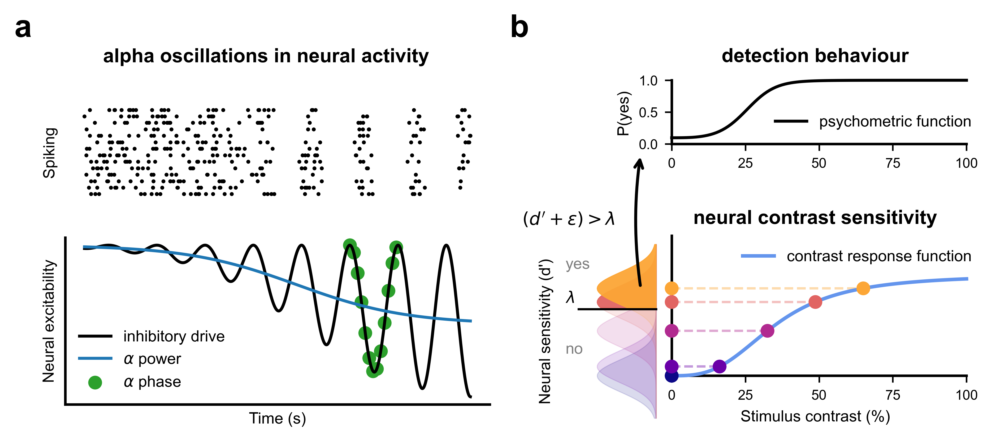

In [2]:
# subplot layout
fig = plt.figure(figsize=(17.6*CM, 7.5*CM), dpi=min_dpi, layout='constrained')

sf = fig.subfigures(1, 2, width_ratios=[1,1.]) 
gs = sf[0].add_gridspec(2,1,height_ratios=[1,1.8])  # spiking/inhibition
axs = [fig.add_subplot(g) for g in gs]
gs1 = sf[1].add_gridspec(2,1,height_ratios=[1,3])
# axs.extend([fig.add_subplot(g) for g in gs1])
axs.append(fig.add_subplot(gs1[1]))
axs.append(fig.add_subplot(gs1[0], sharex=axs[-1]))

# inhibition
ax = axs[1]
dt = 1e-4
xx = np.arange(0,1,dt)
pow = -1 / ( 1 + np.exp(-7*(xx-.55)))
y = pow*(1+np.cos(2*np.pi*xx*8))

ax.plot(xx,y, c='k', label='inhibitory drive')
ax.plot(xx,pow, label=r'$\alpha$ power')
ix = (xx > 5.5/8) & (xx <= 6.5/8) # phase is the points
dx = int(1/dt*(.01))
ax.scatter(xx[ix][::dx], y[ix][::dx], color='C2',label=r'$\alpha$ phase')
ax.legend(frameon=False)
ax.set_yticks([])
ax.set_ylabel('Neural excitability')
ax.set_xlabel('Time (s)')
ax.set_xticks([])

# spiking raster
ax = axs[0]
num_neurons = 14
R = np.ones((xx.size,num_neurons))*50 + y[:,None]*70
Rs = st.uniform.rvs(size=R.shape) < dt*R
# ax.plot(xx,R)
ax.scatter(xx[np.where(Rs)[0]], np.where(Rs)[1], s=1, color='k')
ax.set_xticks([])
ax.set_yticks([])
ax.set_ylabel('Spiking')
ax.spines[['left','bottom']].set_visible(False)

# contrast response function 
ax = axs[2]
x = np.linspace(0,1,100)
Rmax, n, c50, lam = 5, 3, .35, 1.3
d = Rmax * x**n / (x**n + c50**n)
ax.plot(x,d,clip_on=False, zorder=3,  lw=1.8, c='cornflowerblue', label='contrast response function')
ax.legend(frameon=False)

dx = np.linspace(0, .65, 5)
D = Rmax * dx**n / (dx**n + c50**n)
cmap = plt.get_cmap('plasma',1+D.size)
ax.scatter(dx, D, c=cmap(range(D.size)),zorder=3)

yy = np.linspace(-2.1,6.5, 100)
ygap = .053
diststretch = .2
ax.scatter(np.zeros_like(D), D, c=cmap(range(D.size)), zorder=3)
crit = 3.3
for i, di in enumerate(D):
    nz = st.norm.pdf(yy, loc=di, scale=.8)
    nz /= nz.max()
    # ax.fill_betweenx(yy,-nz*diststretch + -ygap, -ygap, clip_on=False, color=cmap(i), alpha=.85, edgecolor='none')
    # plot below and above criterion 
    ax.fill_betweenx(yy[yy<crit],-nz[yy<crit]*diststretch + -ygap, -ygap, clip_on=False, color=cmap(i), alpha=.15, lw=.5 )
    ax.fill_betweenx(yy[yy>=crit],-nz[yy>=crit]*diststretch + -ygap, -ygap, clip_on=False, color=cmap(i), alpha=.95, lw=.5)
    ax.plot([0, dx[i]], np.ones(2)*di, c=cmap(i), ls='--', alpha=.4, lw=1.2)

ax.plot([ax.get_xlim()[0],-ygap], np.ones(2)*crit, lw=1.1, ls='-', c='k') # criterion line

ax.set_xlabel('Stimulus contrast (%)', x=.6)
ax.spines[['left','bottom']].set_position('zero')
ax.spines['bottom'].set_bounds([0,1])
ax.set_yticks([])
ax.set_ylabel("Neural sensitivity (d')", labelpad=60)
ax.set_xticks(np.linspace(0,1,5), labels=np.linspace(0,100,5,dtype=int).round())
ax.spines['left'].set_bounds([0,ax.get_ylim()[1]])
ax.set_title('neural contrast sensitivity', x=.6)
trot = 0
tx = -diststretch*1.8
ax.text(tx,crit+.3,r"$\lambda$", fontsize=8, rotation=trot)
ax.text(tx,crit-2.2,r"no", c='grey', fontsize=8, rotation=trot)
ax.text(tx,crit+2.,r"yes", c='grey', fontsize=8, rotation=trot)

# psychometric function
ax = axs[3]
pr = 1-st.norm.cdf(lam-d)
ax.plot(x,pr, c='k', clip_on=False, label='psychometric function')
ax.set_ylabel(r"P(yes)")
ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_bounds([0,1])
ax.set_ylim([0,1])
ax.set_title('detection behaviour', x=.6, y=1.1)
ax.legend(frameon=False, loc='lower right')

# integral with criterion
con = ConnectionPatch((.19,.74),(.19,-0.2), coordsA=axs[2].transAxes, coordsB=axs[3].transAxes, arrowstyle='->', lw=1.5, connectionstyle='arc3,rad=-0.07')
fig.add_artist(con)
fig.text(.555,.53, r"$(d'+\epsilon) > \lambda$", fontsize=9, ha='center')
# fig.text(.555,.53, r"$Pr(d'+\epsilon > \lambda)$", fontsize=9, ha='center')
# fig.text(.55,.53, r"$\int_{d'+\epsilon>\lambda}p(\epsilon)d\epsilon$", fontsize=10, ha='center')

# sf[0].suptitle('neural responses inhibited\nby alpha oscillations', fontweight='bold', fontsize=plt.rcParams['axes.titlesize'])
sf[0].suptitle('alpha oscillations in neural activity', fontweight='bold', fontsize=plt.rcParams['axes.titlesize'])
fac = 10
fig.get_layout_engine().set(h_pad=fac/72, w_pad=fac/72)

sf[0].text(.0, 1, 'a', fontweight='bold', fontsize=subplot_labelsize, va='center', ha='center')
sf[1].text(0, 1, 'b', fontweight='bold', fontsize=subplot_labelsize, va='center', ha='center')
fig.savefig('theory-fig.png', bbox_inches='tight')

# behavioural and EEG descriptives

## ERP phase relationship

In [9]:
# load data
phase_data = dict()
for i, exp in enumerate(datatypes):
    f = os.path.join(root_folder,exp,'plot-data','phase-erp.mat')
    mat = sio.loadmat(f)
    phase_data[('times',datacodes[i])] = mat['times'].squeeze()
    phase_data[('erp',datacodes[i])] = mat['ERP'].squeeze()

Text(0.5, 0, 'Time [ms]')

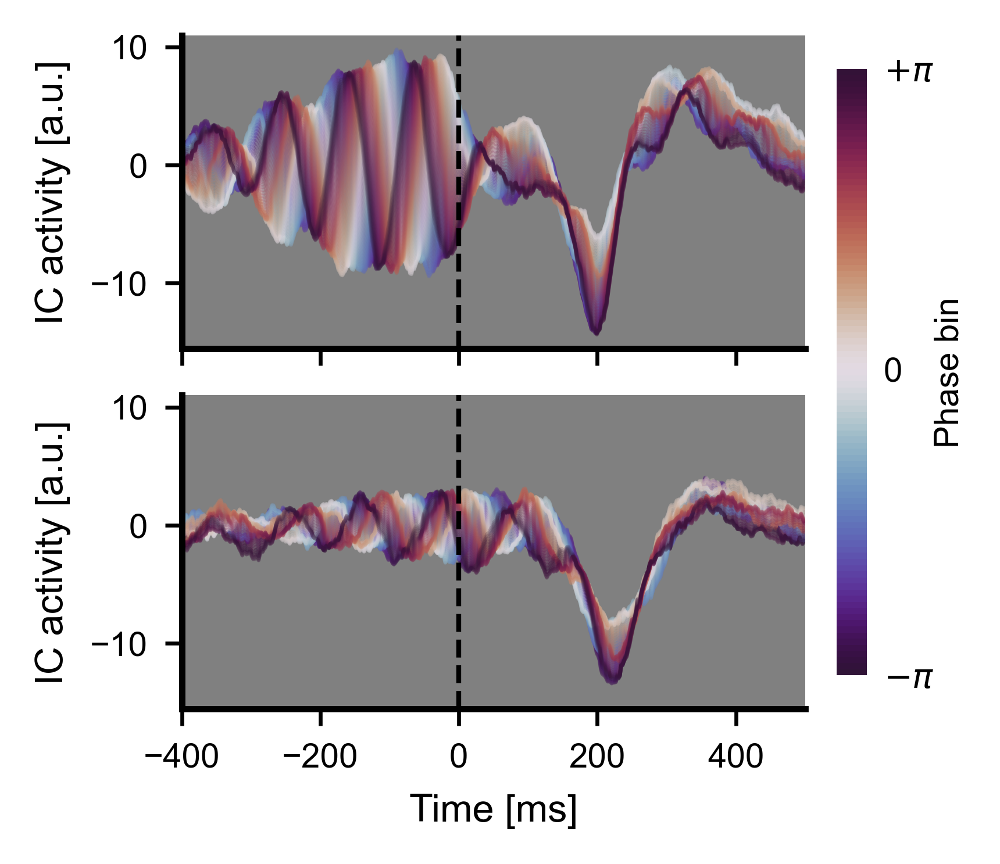

In [10]:
fig, axs = plt.subplots(2,1, figsize=(7*CM, 6*CM), dpi=min_dpi, layout='constrained', sharex=True, sharey=True)

cmap = plt.get_cmap('twilight_shifted', phase_data['erp','1ifc'].shape[1])
norm = mpl.colors.BoundaryNorm(np.arange(phase_data['erp','1ifc'].shape[1]), cmap.N)

conds = datacodes
for i, ax in enumerate(axs):
    times = phase_data['times',conds[i]]
    erp = phase_data['erp',conds[i]].mean(2)

    for j in np.arange(erp.shape[1])[::1]:  # plot lines separately
        ax.plot(times, erp[:, j], alpha=.2, lw=.8, c=cmap(norm(j)))

    ax.axvline(0, lw=1, ls='dashed', c='k')
    ax.set_ylabel('IC activity [a.u.]')
    ax.set_facecolor('0.5')
    # ax.set_title(datanames[i])

# joint colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = plt.colorbar(sm, ax=axs, pad=.05, shrink=.9)
cbar.ax.tick_params(which='both', size=0)
cbar.set_ticks([0, 50, 99], labels=[r'$-\pi$', '0', r'$+\pi$'], fontsize=7)
cbar.set_label('Phase bin', fontsize=7, labelpad=0)
cbar.outline.set_linewidth(0)

ax.set_xlim([-400,500])
ax.set_xlabel('Time [ms]')
# fig.get_layout_engine().set(h_pad=9/72, w_pad=9/72)
# fig.get_layout_engine().set(hspace=.2)
# fig.savefig('erp-phase.svg')

## ERP contrast relationship

In [17]:
# load precomputed contrast ERP data
contr_data = dict()
for i, exp in enumerate(datatypes):
    f = os.path.join(root_folder,exp,'plot-data','contrast-erp.mat')
    mat = sio.loadmat(f)
    contr_data[('times',conds[i])] = mat['times'].squeeze()
    contr_data[('erp',conds[i])] = mat['ERP'].squeeze()

Text(0.5, 0, 'Time [ms]')

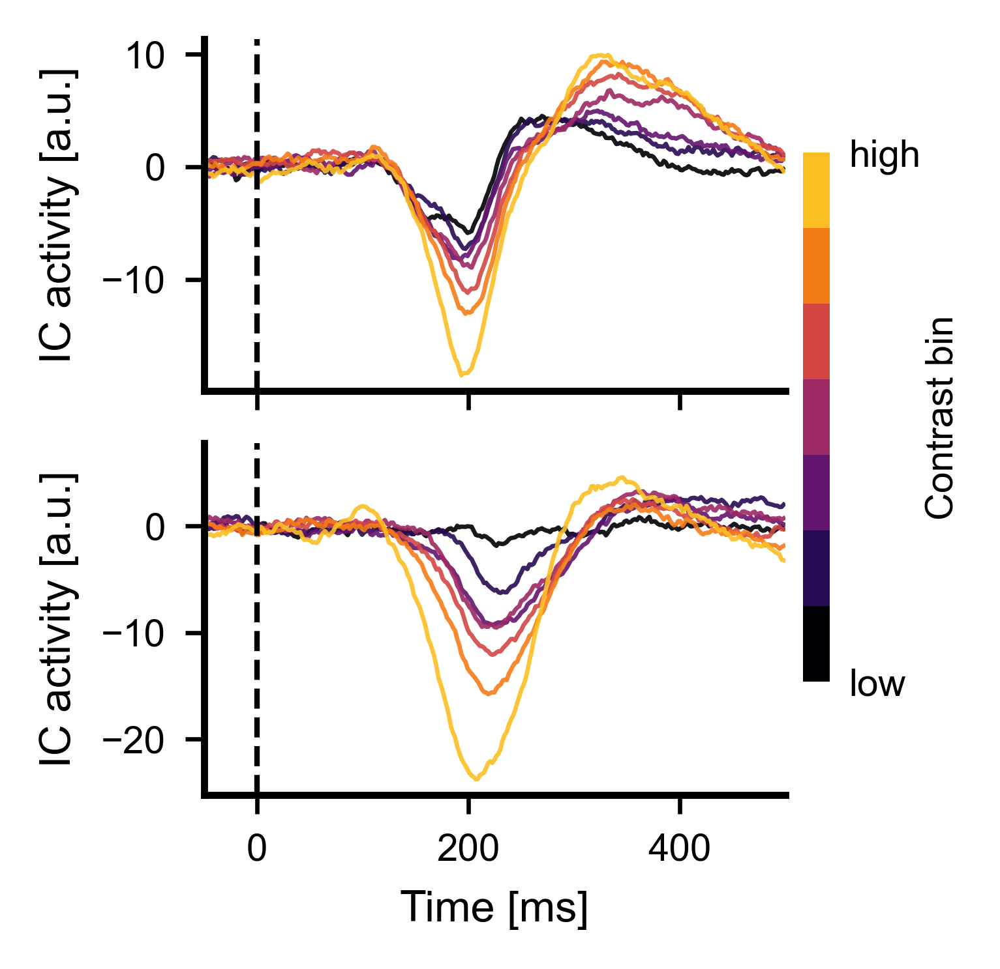

In [18]:
fig, axs = plt.subplots(2,1, figsize=(6.2*CM, 6*CM), dpi=min_dpi, layout='constrained', sharex=True)

N = contr_data['erp','1ifc'].shape[0]
cmap = plt.get_cmap('inferno')(np.linspace(0,.85,N))
cmap = mpl.colors.ListedColormap(cmap)
norm = mpl.colors.BoundaryNorm(np.arange(N+1), cmap.N)

for i, ax in enumerate(axs):
    times = contr_data['times',conds[i]]
    erp = contr_data['erp',conds[i]]

    for j in np.arange(erp.shape[0]):  # plot lines separately
        ax.plot(times, erp[j], alpha=.9, lw=.8, c=cmap(norm(j)))

    ax.axvline(0, lw=1, ls='dashed', c='k')
    ax.set_ylabel('IC activity [a.u.]')
    # ax.set_title(datanames[i])

# joint colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = plt.colorbar(sm, ax=axs, pad=.03, shrink=.7)
cbar.ax.tick_params(which='both', size=0)
cbar.set_ticks([0, N], labels=[r'low', 'high'], fontsize=7)
# cbar.set_ticks([0, 50, 99], labels=[r'$-\pi$', '0', r'$+\pi$'], fontsize=7)
cbar.set_label('Contrast bin', fontsize=7, labelpad=1)
cbar.outline.set_linewidth(0)

ax.set_xlim([-50,500])
ax.set_xlabel('Time [ms]')
# fig.get_layout_engine().set(h_pad=9/72, w_pad=9/72)
# fig.savefig('erp-contrast.svg')

## EEG descriptives

In [327]:
# load IC topographies
topo_data = dict()
for m,c  in zip(datatypes,datacodes): 
    fname = os.path.join(root_folder,m,'plot-data/IC-topo-data.mat')
    mat = sio.loadmat(fname)
    topo_data[c] = mat['group_avg_topo'].flatten()
    labels = np.array([lb[0] for lb in mat['labels'].squeeze()])

# create montage
labels = [l for l in labels if 'EX' not in l]
info = mne.create_info(ch_names=labels, sfreq=512, ch_types='eeg')
info.set_montage('biosemi64')

<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, AF7, AF3, F1, F3, F5, F7, FT7, FC5, FC3, FC1, C1, C3, C5, ...
 chs: 64 EEG
 custom_ref_applied: False
 dig: 67 items (3 Cardinal, 64 EEG)
 highpass: 0.0 Hz
 lowpass: 256.0 Hz
 meas_date: unspecified
 nchan: 64
 projs: []
 sfreq: 512.0 Hz
>

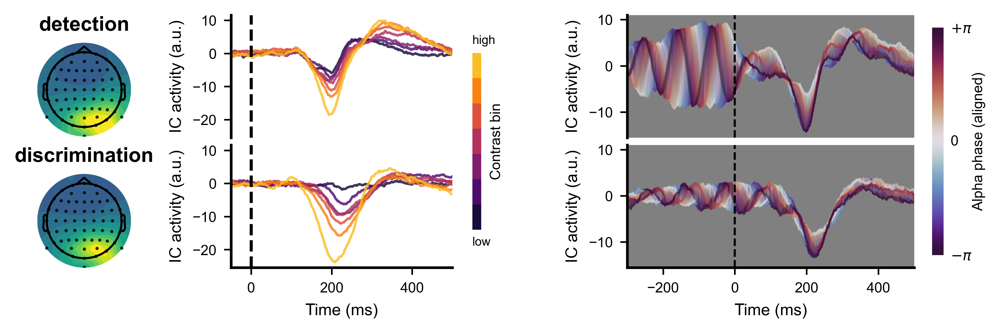

In [14]:
fig = plt.figure(figsize=(17.6*CM, 6*CM), dpi=min_dpi, layout='none', facecolor='1')
# axs = fig.subplots(2,3, width_ratios=[.9,1.8,2])
sf = fig.subfigures(1,3, width_ratios=[.9,1.8,2])
axs = [sf[n].subplots(2,1, sharey=True) for n in range(3)]

# sf[0].subplots_adjust(top=.8, hspace=.4)
sf[1].subplots_adjust(left=.17, right=.8)
fig.subplots_adjust(bottom=.15, hspace=.06, right=.9)
sf[2].subplots_adjust(right=1)
sf[0].subplots_adjust(top=.8, hspace=.4)

# topomaps
mask = np.array([True for i in range(64)])
mask_params = dict(markersize=1.6, alpha=.8, markerfacecolor='k', markeredgecolor='none')
cmap = plt.get_cmap('viridis')
cmap = mpl.colors.LinearSegmentedColormap.from_list('subset_grey', cmap(np.linspace(.3,.99,256)))

for i, (m, ax) in enumerate(zip(datacodes, axs[0].flatten())):
    norm = mpl.colors.BoundaryNorm(np.linspace(-1, np.max(topo_data[m]), 12), 256)

    img, cn = mne.viz.plot_topomap(topo_data[m], info, axes=ax, show=False, sphere='eeglab', res=min_dpi, extrapolate='head', mask=mask, mask_params=mask_params, contours=0, cmap=cmap, cnorm=norm)
    ax.set_title(datanames[i], fontsize=10)

# contrast ERPS
N = contr_data['erp','1ifc'].shape[0]
cmap = plt.get_cmap('inferno')(np.linspace(.1,.85,N))
cmap = mpl.colors.ListedColormap(cmap)
norm = mpl.colors.BoundaryNorm(np.arange(N+1), cmap.N)

for i, (m, ax) in enumerate(zip(datacodes, axs[1].flatten())):
    times = contr_data['times',conds[i]]
    erp = contr_data['erp',conds[i]]

    for j in np.arange(erp.shape[0]):  # plot lines separately
        ax.plot(times, erp[j], alpha=.82, lw=1.2, c=cmap(norm(j)))

    ax.axvline(0, lw=1.5, ls='dashed', c='k')
    ax.set_ylabel('IC activity (a.u.)')

    ax.set_xlim([-50,500])
    if i == 0:
        ax.set_xticks([])
        ax.spines[['bottom']].set_visible(False)

ax.set_xlabel('Time (ms)')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar0 = plt.colorbar(sm, ax=axs[1], pad=.07, shrink=.7)
cbar0.ax.tick_params(which='both', size=0)
# cbar0.set_ticks([0, N], labels=[r'low', 'high'], fontsize=7)
cbar0.set_ticks([])
# cbar.text(.5, 1, 'high')
# cbar.set_ticks([0, 50, 99], labels=[r'$-\pi$', '0', r'$+\pi$'], fontsize=7)
cbar0.set_label('Contrast bin', fontsize=7, labelpad=1)
cbar0.outline.set_linewidth(0)
cbar0.ax.text(0,1.07, 'high', fontsize=6, va='center', ha='left', transform=cbar0.ax.transAxes)
cbar0.ax.text(0,-.07, 'low', fontsize=6, va='center', ha='left', transform=cbar0.ax.transAxes)

# phase
cmap = plt.get_cmap('twilight_shifted', phase_data['erp','1ifc'].shape[1])
norm = mpl.colors.BoundaryNorm(np.arange(phase_data['erp','1ifc'].shape[1]), cmap.N)

for i, (m, ax) in enumerate(zip(datacodes, axs[2].flatten())):
    times = phase_data['times',conds[i]]
    erp = phase_data['erp',conds[i]].mean(2)

    for j in np.arange(erp.shape[1])[::1]:  # plot lines separately
        ax.plot(times, erp[:, j], alpha=.2, lw=.8, c=cmap(norm(j)))

    ax.axvline(0, lw=1, ls='dashed', c='k')
    ax.set_ylabel('IC activity (a.u.)')
    ax.set_facecolor('0.5')

    ax.set_xlim([-300,500])

    if i == 0:
        ax.set_xticks([])
        ax.spines[['bottom']].set_visible(False)
    
ax.set_xlabel('Time (ms)')

# joint colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = plt.colorbar(sm, ax=axs[2], pad=.05, shrink=.9)
cbar.ax.tick_params(which='both', size=0)
cbar.set_ticks([0, 50, 99], labels=[r'$-\pi$', '0', r'$+\pi$'], fontsize=7)
cbar.set_label('Alpha phase (aligned)', fontsize=7, labelpad=0)
cbar.outline.set_linewidth(0)

# fig.subplots_adjust(left=.17, right=.785, hspace=.06, bottom=.15)
# sf[0].subplots_adjust(top=.8, hspace=.4)
fig.savefig('eeg-summary.svg')
# fig.get_layout_engine().set(wspace=.07)

## psychometric function fits


In [15]:
# create plot elements
quant = 1e-2  # amount of quantisation in the contrast values
sizes = []
xxs = [] 
ys = [] 
cs = [] 
psis = []

## detection task
# binned behavioural data
C = df1['c']
C = np.round(C/quant)*quant
xx = np.unique(C)
y = np.zeros_like(xx)
size = np.zeros_like(y)
for i, x in enumerate(xx):
    y[i] = df1[C==x].groupby('p')['y'].mean().mean()
    size[i] = (C==x).sum()

size /= size.max()  # normalise

# compute the function for each mcmc sample
c = xr.DataArray(np.linspace(0,1,100))
p = beh_idata['1ifc'].posterior.copy()
d = 5 * c**p['n'] / (p['c50']**p['n'] + c**p['n'])
psi = st.norm.cdf(d - p['b0'])

# average mcmc sample functions
psi = psi.mean(axis=(1,2,3))

sizes.append(size)
xxs.append(xx)
ys.append(y)
cs.append(c)
psis.append(psi)

## localisation task
quant *= 3  # double bin size
C = df2['c2'] - df2['c1']
C = np.round(C/quant)*quant
xx = np.unique(C)
y = np.zeros(xx.size)
size = np.zeros(y.size)
for i,x in enumerate(xx):
    y[i] = df2[C==x].groupby('p')['y'].mean().mean()
    size[i] = (C==x).sum()

# size[size < 10] = 0
size /= size.max()

# compute the function for each sample of parameters
c = xr.DataArray(np.linspace(-1,1,100))
c1 = np.maximum(0,-c)
c2 = np.maximum(0,c)
p = beh_idata['2afc'].posterior.copy()
d1 = 5 * c1**p['n'] / (p['c50']**p['n'] + c1**p['n'])
d2 = 5 * c2**p['n'] / (p['c50']**p['n'] + c2**p['n'])

psi = p['eps'].values + (1-2*p['eps'].values)*st.norm.cdf(((d2-d1)-p['b0']) / np.sqrt(2))

# average samples to get the mean function (instead of function from mean parameters)
psi = psi.mean(axis=(1,2,3))

sizes.append(size*.65)
xxs.append(xx)
ys.append(y)
cs.append(c)
psis.append(psi)

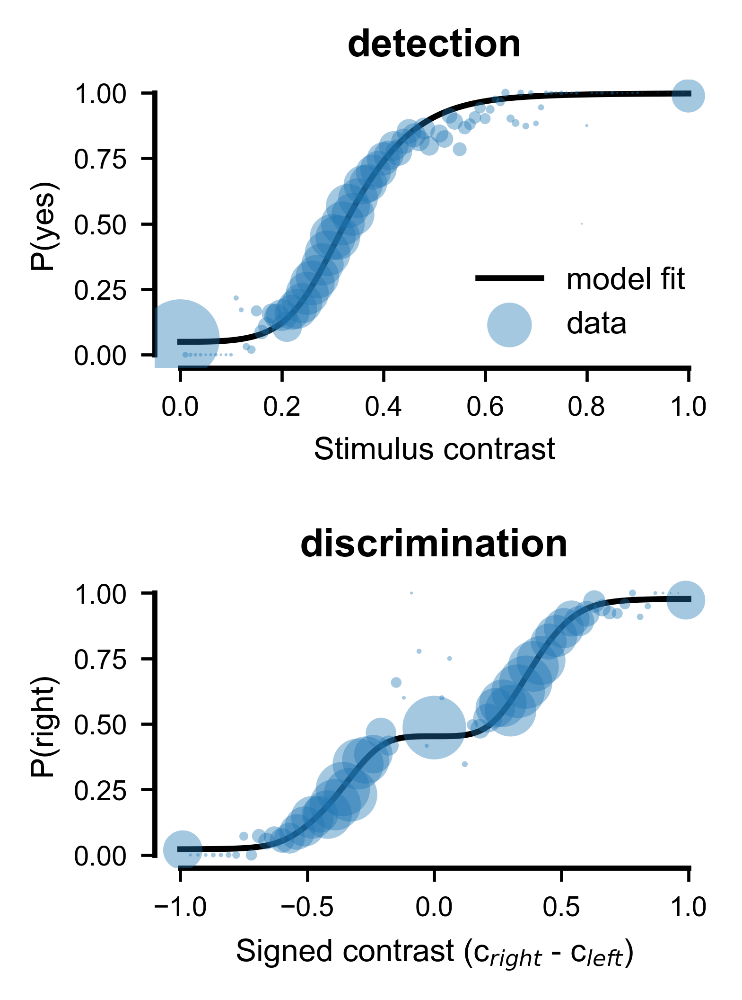

In [16]:
left_from_task_svg = 10.7
task_svg_height = 9
fig, axs = plt.subplots(2,1,figsize=((17.6-left_from_task_svg-.2)*CM, task_svg_height*CM), dpi=min_dpi, layout='constrained')

for i, ax in enumerate(axs):
    # ax.scatter(xxs[i],ys[i],sizes[i]*8e2, alpha=.5, facecolors='none',edgecolors='tab:blue', clip_on=False)
    ax.plot(cs[i], psis[i], c='k', lw=1.5, label='model fit')
    ax.scatter(xxs[i],ys[i],sizes[i]*8e2/2, alpha=.4, edgecolor='none', clip_on=True, zorder=3, label='data')

    ax.spines[['top','right']].set_visible(False)
    ax.spines[['left','bottom']].set_linewidth(1.3)
    ax.spines.left.set_bounds([0,1])
    ax.spines.bottom.set_bounds([0 if i==0 else -1,1])

    ax.set_title(datanames[i])
    if i==0:
        ax.legend(frameon=False, loc='lower right', markerscale=.8)
        ax.set_xlabel(r'Stimulus contrast')
        ax.set_ylabel("P(yes)")
    else:
        ax.set_xlabel(r'Signed contrast (c$_{right}$ - c$_{left}$)')
        ax.set_ylabel("P(right)")
fig.get_layout_engine().set(h_pad=8/72, w_pad=8/72)
fig.savefig('beh-fits.svg')

# binning alpha power and phase

In [19]:
# code ratio contrast
psi_ratio = []
for i, (key, dat) in enumerate(beh_data.items()):
    pids = np.unique(dat['p'])    

    thresholds = np.ones_like(pids).astype(float)
    weights = np.ones_like(pids).astype(float)

    fn = lambda x, thr: np.interp(x, cs[1], psis[i])
    tmp = []
    for j, m in enumerate(pids):
        ix = dat['p'] == m
        contr = dat['contrast'][ix]
        thr = 10**np.mean(np.log10(contr[(contr>0)&(contr<1)]))  # use the 'threshold' found adaptively
        thresholds[j] = thr
        weights[j] = ix.sum()

        match key:
            case 'contrDetectBadpt':
                dat.loc[ix,'ratio_contr'] = contr / thr 
            case 'contrLocalBadpt':
                dat.loc[ix,'ratio_contr'] = dat['C'][ix] / thr


    psi_ratio.append(cs[i]/thresholds.mean()*100)

In [21]:
# binning function for power and contrast
def CRFbin(ydat, contr, x, cbins=8, xbins=4):
    cInd = pd.qcut(contr, cbins, labels=False, duplicates='drop')
    xInd = pd.qcut(x, xbins, labels=False, duplicates='drop')

    dat = np.empty((cbins,xbins))
    for m in range(cbins):
        for n in range(xbins):
            ix = (cInd==m) & (xInd==n)
            dat[m,n] = ydat[ix].mean()
    xs = np.array([contr[cInd==i].mean() for i in np.unique(cInd)])*100 
    return dat, xs

In [22]:
def CRFbin_1IFC(ydat, contr, x, cbins=8, xbins=4):
    cInd = pd.qcut(contr, cbins, labels=False, duplicates='drop')

    dat = np.zeros((np.unique(cInd).size, xbins))
    cvals = np.empty_like(dat[:,0])
    for i, ci in enumerate(np.unique(cInd)):
        ix = cInd == ci # get the contrast bin
        cvals[i] = contr[ix].mean()*100 # store contrast bin center
        xInd = pd.qcut(x[ix], xbins, labels=False, duplicates='drop')
        for j, xbi in enumerate(np.unique(xInd)):
            jx = xInd == xbi
            dat[i,j] = ydat[ix][jx].mean()
    return dat, cvals

def CRFbin_2AFC(ydat, contr, x, side, cbins=5, xbins=4):
    # bin near zero contrasts separately
    zero_mask = (contr<=-.1) | (contr>=.1)
    cInd = np.zeros_like(contr).astype(int)
    cInd[zero_mask] = pd.qcut(np.abs(contr[zero_mask]), cbins, labels=False, duplicates='drop')+1  # ignore contrast sign 
    cInd[~zero_mask] = 0

    dat = np.empty((np.unique(cInd).size,xbins,))

    cvals = np.empty_like(dat[:,0])
    for i, ci in enumerate(np.unique(cInd)):
        ix = cInd == ci # get the contrast bin

        # find the unsigned bin center
        cvals[i] = np.abs(contr[ix][cInd[ix]==ci]).mean()*100

        # bin neural data within contrast bin
        xInd = pd.qcut(x[ix], dat.shape[1], labels=False, duplicates='drop')

        # get the response means dependent on stimulus side
        for m in range(dat.shape[1]):
            lr = side[ix]
            dat[i,m] = ydat[ix][lr & (xInd==m)].mean()
            dat[i,m] += 1-ydat[ix][~lr & (xInd==m)].mean()
            dat[i,m] /= 2 # average both sides
    cvals[0] = 0

    # reverse and concatenate for negative contrasts (stimuli on the other side)
    cvals = np.concatenate((-cvals[::-1], cvals[1:]))
    dat = np.concatenate((1-dat[::-1,:], dat[1:,:]), axis=0)
    return dat, cvals

## combined figure


In [36]:
# bootstapping slopes
nboot = 5000
neural_boots = dict()
boots_file = 'boots_data.pkl'

xbins = 4

if os.path.exists(boots_file):
    # just load if precomputed
    with open(boots_file, 'rb') as f:
        neural_boots = pickle.load(f)
else:  # run boot strapping procedures
    for i, (key, dat) in enumerate(beh_data.items()):
        neural_data = dict(power=dat['pow'], phase=-np.abs(dat['phi']))
        Inds = [np.arange(dat.shape[0]), dat['pow']>0, np.arange(dat.shape[0])]

        for j, (key2, neural_dat) in enumerate(neural_data.items()):
            ydat = dat['y'].values[Inds[j]]
            contr = dat['ratio_contr'].values[Inds[j]]
            neural_dat = neural_dat.values[Inds[j]]

            if key == 'contrLocalBadpt':
                side = (dat['side']=='right').values[Inds[j]]

            res = np.empty((nboot,))
            for n in range(nboot):
                boot_ind = np.random.choice(np.arange(ydat.shape[0]), ydat.shape[0])

                if key == 'contrLocalBadpt':
                    tmp, xval = CRFbin_2AFC(ydat[boot_ind], contr[boot_ind], neural_dat[boot_ind], side[boot_ind], xbins=xbins)
                else:
                    tmp, xval = CRFbin_1IFC(ydat[boot_ind], contr[boot_ind], neural_dat[boot_ind], xbins=xbins)

                x2 = np.arange(tmp.shape[1])
                
                # fit slopes at each contrast bin
                slopes = np.empty((tmp.shape[0]))
                for k in range(tmp.shape[0]):
                    a,b = np.polyfit(x2, tmp[k], 1)
                    slopes[k] = a
                    
                match key:
                    case 'contrDetectBadpt':
                        slopes = np.empty((tmp.shape[0]))
                        for k in range(tmp.shape[0]):
                            a,b = np.polyfit(x2, tmp[k], 1)
                            slopes[k] = a
                        res[n] = slopes.mean()

                    case 'contrLocalBadpt':
                        # include only positive (mirrored slopes)
                        slopes = np.empty_like((xval[xval > 0 ]))
                        tmp = tmp[ xval > 0 ]
                        xval = xval[ xval > 0 ]

                        for k in range(tmp.shape[0]):
                            a,b = np.polyfit(x2, tmp[k], 1)
                            slopes[k] = a

                        res[n] = slopes.mean()

            neural_boots[(key,key2)] = res[~np.isnan(res)]

    with open(boots_file, 'wb') as f:
        pickle.dump(neural_boots, f)

contrDetectBadpt power -0.005 [-0.01  -0.001]
contrDetectBadpt phase -0.003 [-0.007  0.002]
contrLocalBadpt power -0.005 [-0.01  0.  ]
contrLocalBadpt phase -0.001 [-0.006  0.005]


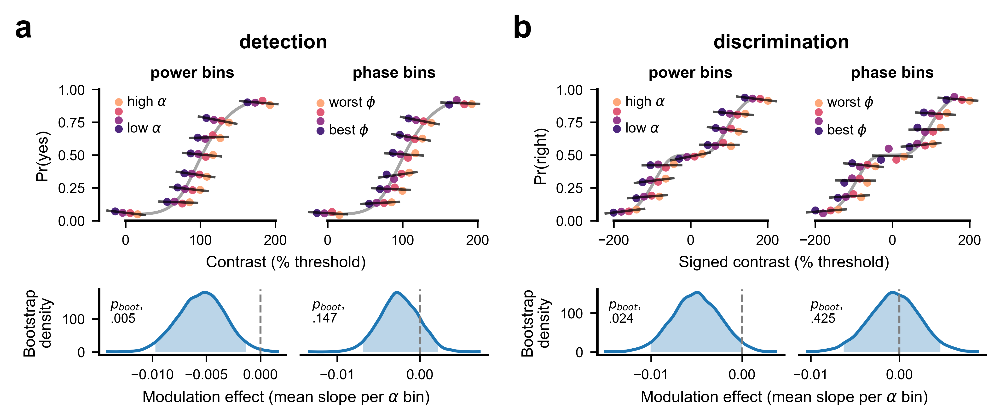

In [24]:
fig = plt.figure(figsize=(17.6*CM, 7*CM), dpi=min_dpi)
sf = fig.subfigures(1,2)
axs = []
for i in range(2):
    axs.append(sf[i].subplots(2,2, height_ratios=[1,.5]))

for i, (lb, ss) in enumerate(zip(['a','b'], sf)):
    ss.suptitle(lb, x=0, y=1, va='top', ha='left')
    ss.text(.54, .95, datanames[i], fontweight='bold', fontsize=10, rotation=0, va='top', ha='center')

xbins = 4

for j in range(2):
    # detection binned data
    for i, ax in enumerate(axs[j][0]):
        df = beh_data[datatypes[j]]
        neural_data = [df['pow'], -np.abs(df['phi'])]
        INDS = [np.arange(df.shape[0]), df['pow']>0]

        if j == 0:
            plot_dat, xs = CRFbin_1IFC(df['y'].values[INDS[i]], df['ratio_contr'].values[INDS[i]], neural_data[i].values[INDS[i]], cbins=8, xbins=xbins)
            jit = .1*100
        else:
            side = (df['side']=='right').values
            plot_dat, xs = CRFbin_2AFC(df['y'].values[INDS[i]], df['ratio_contr'].values[INDS[i]], neural_data[i].values[INDS[i]], side[INDS[i]],cbins=4, xbins=xbins)
            jit = .2*100
        M = plot_dat.shape[1]
        cols = plt.get_cmap('magma', M+2)
        labels = [[r'low $\alpha$']+['']*int(M-2)+[r'high $\alpha$'], [r'best $\phi$']+['']*int(M-2)+[r'worst $\phi$']]

        # plot binned points
        for m in np.arange(M):
            yy = plot_dat[:,m]
            ax.plot(xs+(m-np.floor(M/2))*jit+jit/2, yy, 'o', color=cols(m+1), markersize=4., alpha=.9, markeredgecolor='none')
        
        # regression lines
        for m in np.arange(plot_dat.shape[0]):
            x2 = (np.arange(M)-np.floor(M/2))*jit + jit/2 + xs[m]
            a,b = np.polyfit(x2, plot_dat[m], 1)
            xx = np.linspace(x2.min()-jit, x2.max()+jit, 100)
            y2 = a*xx + b
            ax.plot(xx,y2,'k-', alpha=.7, lw=1.2)
        ax.spines['bottom'].set_bounds([0,200] if j==0 else [-200,200])
        ax.set_title(['power bins','phase bins'][i], fontsize=8)
        ax.set_ylim([0,1])

        ax.legend(labels[i], frameon=False, ncols=1,markerfirst=True,reverse=True,labelspacing=-.3,handletextpad=-.4,handleheight=0, fontsize=7, loc='upper left', borderaxespad=0)

        if i == 0: 
            ax.set_xlabel('Contrast (% threshold)' if j==0 else 'Signed contrast (% threshold)', x=1)
            ax.set_ylabel("Pr(yes)" if j==0 else "Pr(right)")
        else:
            ax.set_yticks([])
            ax.spines['left'].set_visible(False)
        
        xp = psi_ratio[j]
        ix = (xp>xs.min()) & (xp<xs.max())
        psy = psis[j].copy()
        if j==0:
            psy *= .96 # account for binned higher contrasts
        if j==1:
            psy = (psy[len(psy)//2:] + (1-psy[:len(psy)//2][::-1]))/2  # average mirrored
            psy = np.concatenate((1-psy[::-1], psy))  # reconstruct full curve
            psy *= .96
            psy += .02
        ax.plot(xp[ix], psy[ix], c='grey', alpha=.7, zorder=1)
    
# bootstrapped effects
for i, dname in enumerate(datatypes):
    for j, m in enumerate(['power','phase']):
        dat = neural_boots[dname, m]*1
        ax = axs[i][1,j]
        grid, pdf = az.kde(dat)
        ax.plot(grid, pdf, c='C0')
        ax.axvline(0, ls='--', c='grey', lw=1.)

        hdi = az.hdi(dat, hdi_prob=0.95)
        print(dname, m, dat.mean().round(3), hdi.round(3))
        ax.fill_between(grid, 0, pdf, where=(grid>=hdi[0]) & (grid<=hdi[1]), color='C0', alpha=.3, edgecolor='none')

        pval = str((dat>=0).mean().round(3)).removeprefix("0")
        ax.text(.06, .85, f'$p_{{boot}}$,\n{pval}', transform=ax.transAxes, fontsize=6.5, va='top')

        if j==1:
            ax.set_yticks([])
            ax.spines['left'].set_visible(False)

        else:
            ax.set_xlabel(r'Modulation effect (mean slope per $\alpha$ bin)', x=1)
            ax.set_ylabel('Bootstrap\ndensity')

fig.subplots_adjust(left=.17, right=.95, hspace=.7, top=.81, wspace=.08, bottom=.14)
fig.savefig('binning.png')

### extended figure with logistic regression results

In [25]:
LRdat = dict()
for i, exp in enumerate(datatypes):
    f = os.path.join(root_folder, exp, 'plot-data', 'log-reg-IC.mat')
    mat = sio.loadmat(f)
    LRdat[exp,'bic'] = mat['bicw'].flatten()
    LRdat[exp,'aic'] = mat['aicw'].flatten()
    LRdat[exp,'liks'] = mat['liks'].flatten()

contrDetectBadpt power -0.005 [-0.01  -0.001]
contrDetectBadpt phase -0.003 [-0.007  0.002]
contrLocalBadpt power -0.005 [-0.01  0.  ]
contrLocalBadpt phase -0.001 [-0.006  0.005]


/var/folders/51/pgj1q0dx2sb_ysw84nq83ygm0000gn/T/ipykernel_36028/3471616737.py:117: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, fontsize=7, loc='upper right', borderaxespad=0)
/var/folders/51/pgj1q0dx2sb_ysw84nq83ygm0000gn/T/ipykernel_36028/3471616737.py:117: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, fontsize=7, loc='upper right', borderaxespad=0)


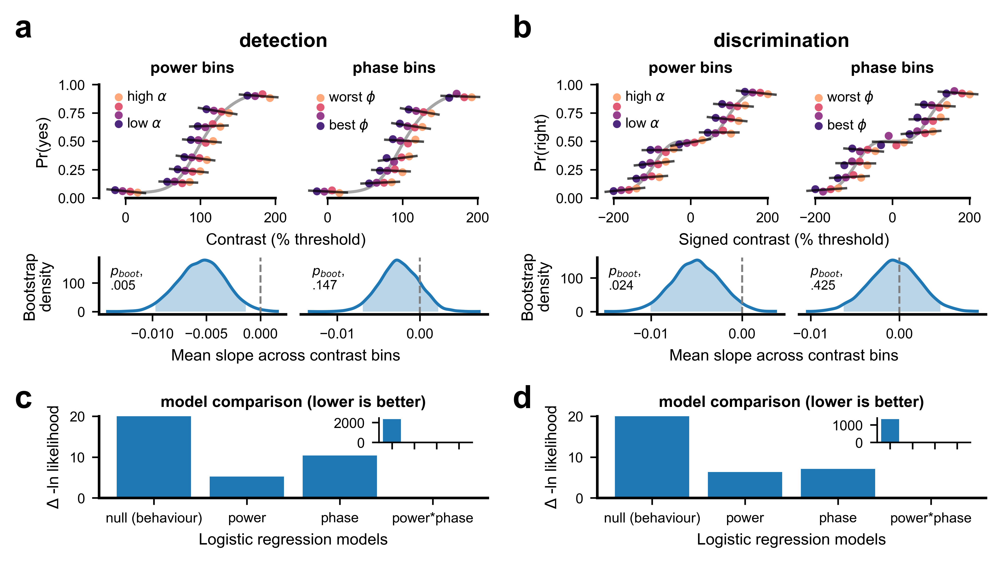

In [35]:
fig = plt.figure(figsize=(17.6*CM, 9.5*CM), dpi=min_dpi)
sf = fig.subfigures(2,2,height_ratios=[2,.9])
axs = []
for i in range(2):
    axs.append(sf[0,i].subplots(2,2, height_ratios=[1,.5]))
axs2 = []
for i in range(2):
    axs2.append(sf[1,i].subplots(1,1))

for i, (lb, ss) in enumerate(zip(['a','b'], sf[0])):
    ss.suptitle(lb, x=0, y=1, va='top', ha='left')
    ss.text(.54, .95, datanames[i], fontweight='bold', fontsize=10, rotation=0, va='top', ha='center')

for i, (lb,ss) in enumerate(zip(['c','d'], sf[1])):
    ss.suptitle(lb, x=0, y=1, va='top', ha='left')

xbins = 4

for j in range(2):
    # detection binned data
    for i, ax in enumerate(axs[j][0]):
        df = beh_data[datatypes[j]]
        neural_data = [df['pow'], -np.abs(df['phi'])]
        INDS = [np.arange(df.shape[0]), df['pow']>0]

        if j == 0:
            plot_dat, xs = CRFbin_1IFC(df['y'].values[INDS[i]], df['ratio_contr'].values[INDS[i]], neural_data[i].values[INDS[i]], cbins=8, xbins=xbins)
            jit = .1*100
        else:
            side = (df['side']=='right').values
            plot_dat, xs = CRFbin_2AFC(df['y'].values[INDS[i]], df['ratio_contr'].values[INDS[i]], neural_data[i].values[INDS[i]], side[INDS[i]],cbins=4, xbins=xbins)
            jit = .2*100
        M = plot_dat.shape[1]
        cols = plt.get_cmap('magma', M+2)
        labels = [[r'low $\alpha$']+['']*int(M-2)+[r'high $\alpha$'], [r'best $\phi$']+['']*int(M-2)+[r'worst $\phi$']]

        # plot binned points
        for m in np.arange(M):
            yy = plot_dat[:,m]
            ax.plot(xs+(m-np.floor(M/2))*jit+jit/2, yy, 'o', color=cols(m+1), markersize=4., alpha=.9, markeredgecolor='none')
        
        # regression lines
        for m in np.arange(plot_dat.shape[0]):
            x2 = (np.arange(M)-np.floor(M/2))*jit + jit/2 + xs[m]
            a,b = np.polyfit(x2, plot_dat[m], 1)
            xx = np.linspace(x2.min()-jit, x2.max()+jit, 100)
            y2 = a*xx + b
            ax.plot(xx,y2,'k-', alpha=.7, lw=1.2)
        ax.spines['bottom'].set_bounds([0,200] if j==0 else [-200,200])
        ax.set_title(['power bins','phase bins'][i], fontsize=8)
        ax.set_ylim([0,1])

        ax.legend(labels[i], frameon=False, ncols=1,markerfirst=True,reverse=True,labelspacing=-.3,handletextpad=-.4,handleheight=0, fontsize=7, loc='upper left', borderaxespad=0)

        if i == 0: 
            ax.set_xlabel('Contrast (% threshold)' if j==0 else 'Signed contrast (% threshold)', x=1)
            ax.set_ylabel("Pr(yes)" if j==0 else "Pr(right)")
        else:
            ax.set_yticks([])
            ax.spines['left'].set_visible(False)
        
        xp = psi_ratio[j]
        ix = (xp>xs.min()) & (xp<xs.max())
        psy = psis[j].copy()
        if j==0:
            psy *= .96 # account for binned higher contrasts
        if j==1:
            psy = (psy[len(psy)//2:] + (1-psy[:len(psy)//2][::-1]))/2  # average mirrored
            psy = np.concatenate((1-psy[::-1], psy))  # reconstruct full curve
            psy *= .96
            psy += .02
        ax.plot(xp[ix], psy[ix], c='grey', alpha=.7, zorder=1)
    
# bootstrapped effects
for i, dname in enumerate(datatypes):
    for j, m in enumerate(['power','phase']):
        dat = neural_boots[dname, m]*1
        ax = axs[i][1,j]
        grid, pdf = az.kde(dat)
        ax.plot(grid, pdf, c='C0')
        ax.axvline(0, ls='--', c='grey', lw=1.)

        hdi = az.hdi(dat, hdi_prob=0.95)
        print(dname, m, dat.mean().round(3), hdi.round(3))
        ax.fill_between(grid, 0, pdf, where=(grid>=hdi[0]) & (grid<=hdi[1]), color='C0', alpha=.3, edgecolor='none')

        pval = str((dat>=0).mean().round(3)).removeprefix("0")
        ax.text(.06, .85, f'$p_{{boot}}$,\n{pval}', transform=ax.transAxes, fontsize=6.5, va='top')

        if j==1:
            ax.set_yticks([])
            ax.spines['left'].set_visible(False)

        else:
            ax.set_xlabel(r'Mean slope across contrast bins', x=1)
            ax.set_ylabel('Bootstrap\ndensity')

# likelihood ratio panels
for i, exp in enumerate(datatypes):
    ax = axs2[i]
    liks = LRdat[exp,'liks']
    liks = -(liks-liks.max())
    ax.bar(np.arange(len(liks)), liks)
    ax.set_ylim([0,20])

    x = np.arange(len(liks))

    ax.set_xticks(x, labels=['null (behaviour)','power','phase','power*phase'])
    ax.set_ylabel(r'$\Delta$ -ln likelihood')
    ax.set_title('model comparison (lower is better)', y=.97, fontsize=8)
    ax.legend(frameon=False, fontsize=7, loc='upper right', borderaxespad=0)

    ax2h = .3
    ax2w = .24
    ax2 = ax.inset_axes([1-ax2w-.04, 1-ax2h-.02, ax2w, ax2h])
    ax2.bar(np.arange(len(liks)), liks)
    ax2.set_xticks(np.arange(len(liks)), labels=['']*len(liks))
    ax2.spines[['left','bottom']].set_linewidth(.8)

    # d = .5  # proportion of vertical to horizontal extent of the slanted line
    # kwargs = dict(marker=[(-1, -d), (1, d)], markersize=8,
                # linestyle="none", color='k', mec='k', mew=1, clip_on=False)
    # ax.plot([0,0], [0, 1], transform=ax.transAxes, **kwargs)  
    # ax2.spines['bottom'].set_bounds([0,3])

    # ax.set_ylim([0,1])
    # ax.spines['left'].set_bounds([0,1])
    ax.set_xlabel('Logistic regression models')

fig.subplots_adjust(left=.17, right=.95, hspace=.7, top=.81, wspace=.08, bottom=.19)
for i in range(2):
    sf[1,i].subplots_adjust(left=.17, right=.95, hspace=.7, top=.81, wspace=.08, bottom=.32)
fig.savefig('binning.png')

# parameter posteriors

In [29]:
# model_output_folder = 'C:/Users/henry/Documents/osl-psyc-model-fits'
# model_output_folder = '/Volumes/CONSENPHAS-Q5078/osl-psyc-model-fits'
model_output_folder = os.path.join(root_folder, 'osl-psyc-model-fits')
os.path.exists(model_output_folder)

True

In [30]:
model_types = ['Cg','g','Nz','b']
model_names = ['contrast gain', 'response gain', 'noise', 'criterion']
data_types = ['1IFC','2AFC']

models = dict()
for dt in data_types:
    models[dt] = dict()
    for ft in model_types:
        if (dt=='1IFC') and (ft in ['b','g']):
            file = os.path.join(model_output_folder, f'inhib-model-{dt}-fit-bg.nc')
        else:
            file = os.path.join(model_output_folder, f'inhib-model-{dt}-fit-{ft}.nc')
        trace = az.from_netcdf(file)
        models[dt][ft] = trace
        print(trace.sample_stats.diverging.sum(axis=1).values)

[0 0 0 0]
[0 0 0 0]
[0 0 0 0]
[0 0 0 0]
[0 0 0 0]
[0 0 0 0]
[0 0 0 0]
[0 1 0 0]


In [ ]:
# calculate the normalisation constants for each data type (to stretch posteriors to same scale visually)
norm_consts = dict()
for dt in data_types:
    tmp = []
    for m in model_types:
        mu = models[dt][m].posterior[f'mu_{m}']
        sigma = models[dt][m].posterior['sigma'].sel(param=m)
        dat = mu / sigma.median()
        tmp.append(np.abs(dat).max().values)
    norm_consts[dt] = np.array(tmp).max()
norm_consts

{'1IFC': np.float64(9.317606770486224), '2AFC': np.float64(7.259006302194021)}

1IFC Cg -0.899 [-2.113  0.227] bf10: 0.73 P: 0.057
1IFC g -3.388 [-5.413 -1.253] bf10: 20.27 P: 0.0
1IFC Nz 0.167 [-0.79   1.087] bf10: 0.62 P: 0.343
1IFC b -2.814 [-5.497 -0.191] bf10: 5.49 P: 0.017
2AFC Cg -1.509 [-3.382  0.3  ] bf10: 1.03 P: 0.048
2AFC g -2.499 [-4.256 -0.48 ] bf10: 3.16 P: 0.004
2AFC Nz 1.283 [-0.325  3.07 ] bf10: 0.89 P: 0.064
2AFC b 0.556 [-0.127  1.339] bf10: 0.66 P: 0.058


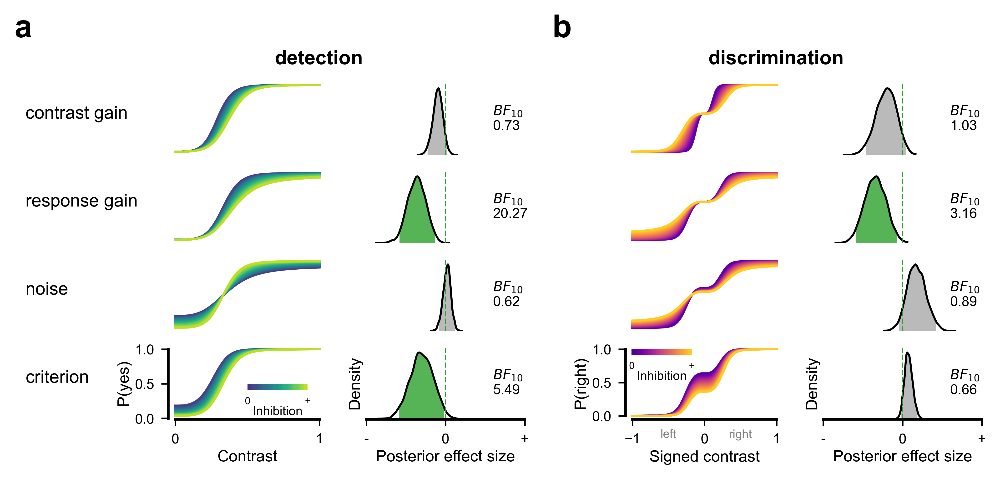

In [59]:
# figure setup 
fig = plt.figure(figsize=(17.6*CM,8*CM),dpi=min_dpi,facecolor="1")
sf = fig.subfigures(1,3, width_ratios=[.5,3,3])
axs0 = sf[1].subplots(4,2)
axs1 = sf[2].subplots(4,2)

sf[0].suptitle('a', va='top',ha='left', x=0, y=1)
sf[2].suptitle('b', va='top',ha='left', x=.01, y=1)

for ax in np.concatenate([axs0.flatten(), axs1.flatten()]):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines[['left','bottom']].set_visible(False)

# model labels
for i, ax in enumerate(axs0[:,0]):
    ax.text(-.9, .5, model_names[i], fontweight='normal', fontsize=9, ha='left', transform=ax.transAxes)
    # ax.text(-.6, .5, model_names[i], fontweight='normal', fontsize=9, ha='center', transform=ax.transAxes)

# data type labels
for i, ss in enumerate(sf[1:]):
    ss.text(.5, .92, 'detection' if i==0 else 'discrimination', fontweight='bold', fontsize=10, va='top', ha='center')

# plot the model posteriors
for axs, d in zip([axs0[:,1],axs1[:,1]], data_types):
    for i, (ax, m) in enumerate(zip(axs, model_types)):
        mu = models[d][m].posterior[f'mu_{m}']
        sigma = models[d][m].posterior['sigma'].sel(param=m)
        dat = mu / sigma.mean()
        # print(d,m,bf10_from_B(dat.mean().values).round(3))
        bf = bf10_from_B(dat.mean().values).round(2)

        # hdi 
        hdi = az.hdi(dat.values.flatten(), hdi_prob=.95)
        pval = (dat>0).mean().values.round(3) if dat.mean().values<0 else (dat<0).mean().values.round(3)

        print(d,m, dat.mean().values.round(3), hdi.round(3), f'bf10: {bf.round(3)}', f'P: {pval}')

        # plot distribution
        grid, pdf =  az.kde(dat.values.flatten())
        # normF = np.abs(grid).max()  # per-model normalisation
        normF = norm_consts[d]
        hdi /= normF  # normalise
        grid /= normF
        pdf /= np.abs(pdf).max()
        ax.plot(grid, pdf, c='k', lw=1)
        ax.set_xlim([-1,1])
        ax.axvline(0, ls='--', c='C2', lw=.7)

        # fill HDI
        ax.fill_between(grid, 0, pdf, where=(grid>hdi[0])&(grid<hdi[1]), color='darkgrey' if hdi[0]<=0<=hdi[1] else 'C2', alpha=.8, edgecolor='none')

        ax.set_ylim([0, 1.1])
        ax.text(.8, .5, f'$BF_{{10}}$\n{bf}', transform=ax.transAxes, ha='left', va='center', fontsize=7)

        if i == len(model_types)-1:
            ax.spines['bottom'].set_visible(True)
            ax.set_xticks([-1,0,1], labels=['-','0','+'])
            ax.set_xlabel('Posterior effect size', labelpad=2)
            ax.set_ylabel('Density', labelpad=2)

# visualise the model effects on performance
Rmax, c50, n = 5, .4, 3
K = 30  # number of lines to draw
for axs, dt in zip([axs0[:,0],axs1[:,0]], data_types):
    dat = dict()
    match dt:
        case '1IFC':
            x = np.linspace(0,1,100)[:,None]
            lam = 1.8
            Rs = np.logspace(np.log10(3.5), np.log10(5), K)[::-1]
            c50s = np.linspace(.35,.45,K)
            nz = np.linspace(1,2.2,K)[::-1]
            lams = np.linspace(.9,1.8,K)
            cmap = plt.get_cmap('viridis',K+1)
            cmap = mpl.colors.ListedColormap(cmap(np.linspace(.15,.9,K)))

            # contrast gain 
            d = Rmax*x**n / (x**n + c50s[None,:]**n)
            dat['contrast gain'] = 1-st.norm.cdf(lam-d)

            # response gain 
            d = Rs[None,:]*x**n / (x**n + c50**n)
            dat['response gain'] = 1-st.norm.cdf(lam-d)

            # noise
            d = Rmax*x**n / (x**n + c50**n)
            dat['noise'] = 1-st.norm.cdf((lam-d)/nz[None,:])

            # criterion 
            dat['criterion'] = 1-st.norm.cdf(lams[None,:]-d)

        case '2AFC':
            c1 = np.maximum(np.linspace(-1,1,100),0)[:,None]
            c0 = np.flip(c1)
            x = c1 - c0
            lam = -.25
            Rs = np.logspace(np.log10(2.), np.log10(5.5), K)[::-1]
            c50s = np.linspace(.2, .5, K)
            nz = np.linspace(1,2.5,K)[::1]
            lams = np.linspace(-.5,.5,K)
            cmap = plt.get_cmap('plasma')
            cmap = mpl.colors.ListedColormap(cmap(np.linspace(.1,.9,K)))

            # contrast gain
            d1 = Rmax*c1**n / (c1**n + c50s[None,:]**n)
            d0 = Rmax*c0**n / (c0**n + c50s[None,:]**n)
            dat['contrast gain'] = 1-st.norm.cdf((lam-(d1-d0))/np.sqrt(2))

            # response gain
            d1 = Rs[None,:]*c1**n / (c1**n + c50**n)
            d0 = Rs[None,:]*c0**n / (c0**n + c50**n)
            dat['response gain'] = 1-st.norm.cdf((lam-(d1-d0))/np.sqrt(2))

            # noise
            d1 = Rmax*c1**n / (c1**n + c50**n)
            d0 = Rmax*c0**n / (c0**n + c50**n)
            dat['noise'] = 1-st.norm.cdf(((-.35-(d1-d0))/nz[None,:])/np.sqrt(2))

            # criterion
            dat['criterion'] = 1-st.norm.cdf((lams[None,:]-(d1-d0))/np.sqrt(2)) 

    for i, (ax, m) in enumerate(zip(axs, model_names)):
        for j in range(K):
            ax.plot(x, dat[m][:,j], c=cmap(j), alpha=.9, lw=1.1)
        
        if i == len(model_names)-1:
            ax.spines[['bottom','left']].set_visible(True)
            ax.set_xticks([0,1] if dt=='1IFC' else [-1,0,1])
            ax.spines['bottom'].set_bounds([0,1] if dt=='1IFC' else [-1,1])
            ax.set_yticks([0, .5, 1])
            ax.spines['left'].set_bounds([0,1])
            ax.set_ylabel(r"P(yes)" if dt=='1IFC' else r"P(right)", labelpad=2)
            ax.set_xlabel('Contrast' if dt=='1IFC' else 'Signed contrast', labelpad=2)

            if dt == '2AFC':
                ax.text(-.5,-.28, 'left', fontsize=6, ha='center', va='center', color='grey', transform=ax.transData)
                ax.text(.5,-.28, 'right', fontsize=6, ha='center', va='center', color='grey', transform=ax.transData)

            # colobar
            axin = ax.inset_axes([.5,.4, .38, .08] if dt=='1IFC' else [.04,.88, .38, .08])
            axin.spines[['left','bottom']].set_visible(False)
            axin.set_xticks([])
            axin.set_yticks([])
            cb = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap), cax=axin, orientation='horizontal', )
            cb.outline.set_linewidth(0)
            cb.ax.tick_params(which='both', size=0)
            cb.set_ticks([0,1],labels=[0,'+'], fontsize=5)
            cb.set_label('Inhibition', fontsize=6.3, labelpad=0)

fig.subplots_adjust(left=.17, right=.95, top=.85, bottom=.1, hspace=0.2, wspace=.25)
fig.savefig('inhib-models.png')

# inhibition profile

In [70]:
# compute model estimated inhibition using per trial phase and power
Ms = []
gs = []
for d, (_,df) in zip(data_types, beh_data.items()): 
    if d == '1IFC':
        m = models[d]['b']
    else:
        m = models[d]['g']
    
    Ms.append(m.posterior['m'])
    gs.append(m.posterior['g'])

    print(d, Ms[-1].mean().values.round(3), az.hdi(Ms[-1].values.flatten(), hdi_prob=.95).round(3))

1IFC 0.34 [0.064 0.662]
2AFC 0.283 [0.021 0.601]


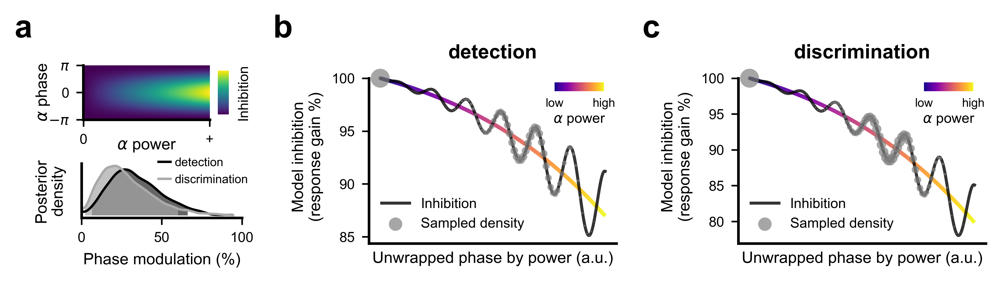

In [60]:
fig = plt.figure(figsize=(17.6*CM,4.5*CM), dpi=min_dpi)
sf = fig.subfigures(1,3, width_ratios=[.7, 1,1])

# fig.subplots_adjust(left=.8, top=.85, right=.93, bottom=.2)
# sf[0].subplots_adjust(hspace=.8, bottom=.2)
fig.subplots_adjust(left=.26, top=.80, right=.93, bottom=.2)

axs = []
axs.append(sf[0].subplots(2,1))
axs.append(sf[1].subplots(1,1))
axs.append(sf[2].subplots(1,1))

for lab, ss in zip(['a','b','c'], sf):
    ss.suptitle(lab, x=0, y=1, ha='left', va='top')

# plot the inhibition link function
ax = axs[0][0]
phase = np.linspace(-np.pi, np.pi, 300)[:,None]
pow = np.linspace(0,1.5,300)[None,:]
I = pow * (1+np.cos(phase))
pcm = ax.pcolormesh(pow.flatten(), phase.flatten(), I, cmap='viridis')
ax.set_aspect(1/9.7)
ax.set_xticks([0,1.5,], labels=[0,'+'])
ax.set_xlabel(r'$\alpha$ power', labelpad=-4)
ax.set_ylabel(r'$\alpha$ phase', labelpad=-1)
ax.set_yticks([-np.pi, 0, np.pi], labels=[r'$-\pi$', '0', r'$\pi$'])
cb = sf[0].colorbar(pcm, ax=ax, aspect=4, shrink=.8)
cb.set_ticks([])
cb.set_label('Inhibition', fontsize=7)
cb.outline.set_linewidth(0)

# plot the posterior distributions of m
ax = axs[0][1]
cols = ['k','darkgrey']
As = [.6, .7]
for i, d in enumerate(Ms):
    grid, pdf = az.kde(100*d.values.flatten())
    # pdf /= np.abs(pdf).max()
    ax.plot(grid, pdf, c=cols[i], lw=1.2, label=datanames[i], alpha=1)

    hdi = az.hdi(100*d.values.flatten(), hdi_prob=.95)
    ax.fill_between(grid, 0, pdf, where=(grid>hdi[0])&(grid<hdi[1]), color=cols[i], alpha=As[i], edgecolor='none')
ax.set_xlim([0,100])
ax.legend(frameon=False, fontsize=6, markerfirst=True, reverse=False, borderpad=-1, handlelength=1, handletextpad=.35)
ax.set_xlabel('Phase modulation (%)')
ax.set_ylabel('Posterior\ndensity', labelpad=8)
ax.set_yticks([])

for i, ax in enumerate(axs[1:]):
    m = Ms[i].values.flatten()  # samples
    df = beh_data[datatypes[i]]
    g = gs[i].values.flatten().mean()

    # compute the phase unwraped inhibition profile (showing change in phase (time) and concurrent change in power)
    N = 400
    xmax = 2*np.pi * 6.5
    pmax = df['pow'].max()  # display up to the max observed log1p power
    xx = np.linspace(0, xmax, N)
    pow = np.expm1(np.linspace(0,pmax,N))

    I = pow*(1+m.mean()*np.cos(xx))
    Imax = np.abs(I).max()
    I /= Imax
    rescale = np.abs(pmax*(1+m.mean()*np.cos(xx))).max() # rescale to match maximum log1p power
    I *= rescale

    ax.plot(xx, 100*np.exp(g*I), c='k', alpha=.8, zorder=4)

    # project data pairs (pow,phase) to nearest points in the joint function of power at unwrapped angle xx
    xP = pow
    xphi = (xx+np.pi) % (2*np.pi) - np.pi
    loss = (xP-np.expm1(df['pow'].values[:,None]))**2 + (xphi-df['phi'].values[:,None])**2
    X = xx[np.argmin(loss, axis=1)]

    # bin projected X values and count
    xbins = np.linspace(xx.min(), xx.max(), 100)
    binInds = np.digitize(X, xbins, right=True)
    counts = np.array([np.sum(binInds==i) for i in range(len(xbins)-1)]).astype(float)
    counts /= counts.max()
    y_at_xbins = 100*np.exp(g*I)[np.argmin((xx-xbins[:,None])**2, axis=1)]
    ax.scatter(xbins[:-1], y_at_xbins[:-1], counts*90, alpha=.7, edgecolor='none', color='grey', zorder=8, clip_on=False)
    # yy = np.ones_like(xbins[:-1])*100
    # ax.scatter(xbins[:-1], yy, counts*90, alpha=.9, edgecolor='none', color='grey', zorder=8, clip_on=False)

    # colorbar for the coloured line
    colored_line(xx, 100*np.exp(g*pow/Imax*rescale), c=np.linspace(0,1,xx.size), ax=ax, cmap='plasma', lw=2, zorder=3, alpha=1)
    axin = ax.inset_axes([.75, .88, .2,.05])
    cb = fig.colorbar(mpl.cm.ScalarMappable(cmap='plasma'), cax=axin, orientation='horizontal', )
    cb.outline.set_linewidth(0)
    cb.ax.tick_params(which='both', size=0)
    cb.set_ticks([0,1],labels=['low','high'], fontsize=6)
    cb.set_label(r'$\alpha$ power', fontsize=7, labelpad=2)

    ax.set_title(datanames[i])
    ax.set_xticks([])
    ax.set_xlabel('Unwrapped phase by power (a.u.)')
    ax.set_ylabel(f'Model inhibition\n(response gain %)')
    ax.spines['left'].set_bounds([ax.get_ylim()[0], 100])
    ax.legend(['Inhibition','Sampled density'], frameon=False, fontsize=7, loc='best')

sf[0].subplots_adjust(hspace=.8, right=.88)
sf[1].subplots_adjust(top=.78, bottom=.1, right=.93)
sf[2].subplots_adjust(top=.78, bottom=.1)
fig.savefig('inhib-profile.png')

# supplementary figures

## model comparisons

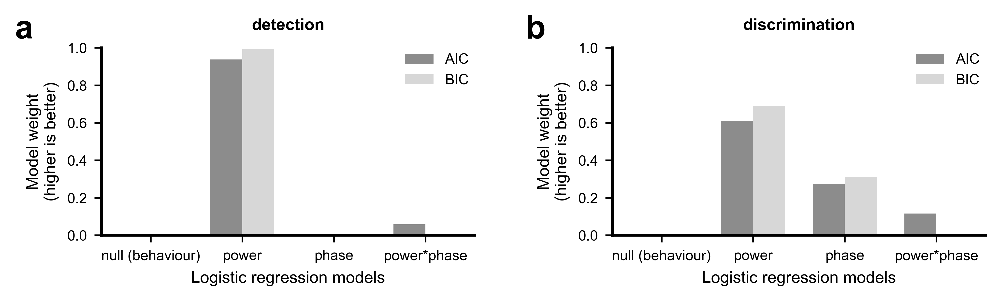

In [64]:
fig = plt.figure(figsize=(17.6*CM, .5*9.5*CM), dpi=min_dpi)
sf = fig.subfigures(1,2)

axs = []
for i in range(2):
    axs.append(sf[i].subplots())
    sf[i].suptitle(['a','b'][i], x=0, y=1, va='top', ha='left')

for i, exp in enumerate(datatypes):
    ax = axs[i]
    bic = LRdat[exp, 'bic']
    aic = LRdat[exp, 'aic']

    width = 0.35
    x = np.arange(len(bic))

    ax.bar(x - width/2, aic, width, label='AIC', color='grey', alpha=.9, clip_on=False)
    ax.bar(x + width/2, bic, width, label='BIC', color='lightgrey', alpha=.9, clip_on=False)

    ax.set_xticks(x, labels=['null (behaviour)','power','phase','power*phase'])
    ax.set_ylabel(f'Model weight\n(higher is better)')
    ax.set_title(f'{datanames[i]}', y=1.03, fontsize=8)
    ax.legend(frameon=False, fontsize=7, loc='upper right', borderaxespad=0)
    ax.set_ylim([0,1])
    ax.set_xlabel('Logistic regression models')

fig.subplots_adjust(left=.17, bottom=.2)
fig.savefig('supp-fig-model-weights.png')

## EEG descriptives

In [134]:
# load data
eeg_data = dict()

for m, c in zip(datatypes, datanames):
    # topographies
    fname = os.path.join(root_folder, m, 'plot-data', 'ic-topos.mat')
    mat = sio.loadmat(fname)
    eeg_data[(c,'topos')] = mat['maps'] # 64x32

    # erps 
    fname = os.path.join(root_folder, m, 'plot-data', 'ic-erp.mat')
    mat = sio.loadmat(fname)
    eeg_data[(c,'erps')] = mat['ERP']  # 8x4xtimes
    eeg_data[(c,'times')] = mat['times'].flatten()  # times

    # power spectra
    fname = os.path.join(root_folder, m, 'plot-data', 'IC-freq-data.mat')
    mat = sio.loadmat(fname)
    eeg_data[(c,'pow')] = mat['pow']  # freqs x trials
    eeg_data[(c,'freqs')] = mat['f'].flatten()  # freqs
    
    # trial data
    fname = os.path.join(root_folder,m,'derivatives/eeg/ic/compiled-data-struct.mat')
    eeg_data[(c,'trial_dat')] = load_data(fname)

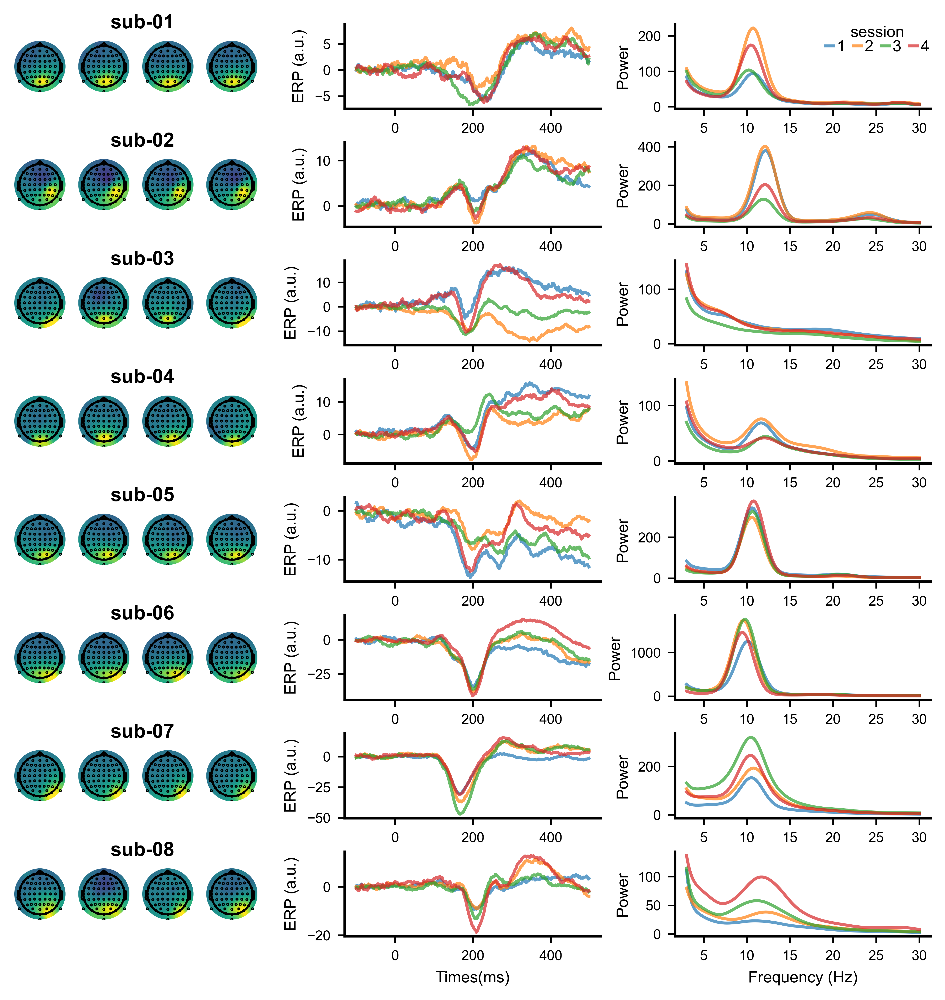

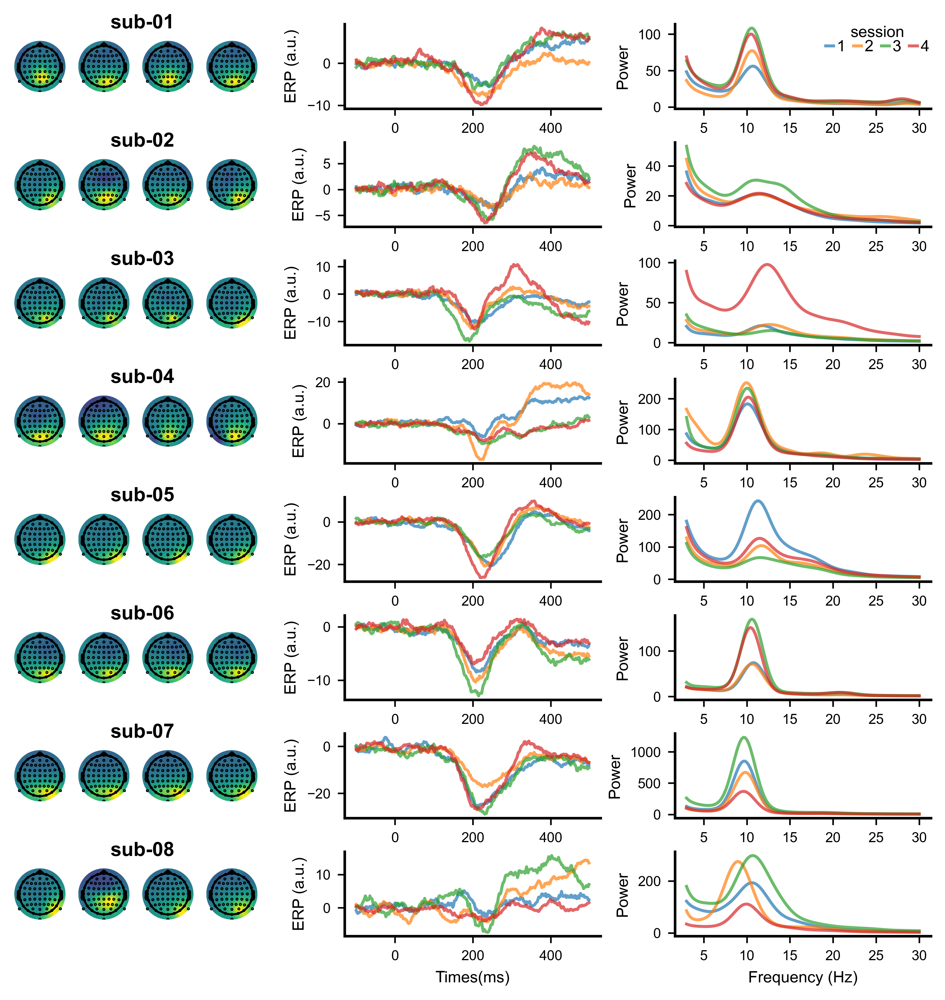

In [302]:
calpha=.7
for c,m in zip(datanames,datatypes):
    times = eeg_data[c,'times']
    erps = eeg_data[c,'erps']
    pow = eeg_data[c,'pow']
    freqs = eeg_data[c,'freqs']
    topos = eeg_data[c,'topos']

    df = eeg_data[c,'trial_dat']
    
    fig = plt.figure(figsize=(17.6*CM,17.6*CM), dpi=min_dpi)
    sf = fig.subfigures(1,3)
    axs = []
    for i in range(3):
        axs.append(sf[i].subplots(8,1))
        # sf[i].suptitle(['a','b','c'][i], x=0, y=1, va='top', ha='left')
    
    for i in range(8):
        ax = axs[1][i]
        # ax.set_title(f'sub-0{i+1}', x=-.45, y=.5)

        # plot ERPS per session
        t_ind = (times>=-100) & (times<=500)
        ax.plot(times[t_ind], erps[i].T[t_ind,:], alpha=calpha)
        if i == 7:
            ax.set_xlabel('Times(ms)')
        ax.set_ylabel('ERP (a.u.)')

        # plot power spectra
        ax = axs[2][i]
        f_ix = (freqs>=3) & (freqs<=30)
        for j in range(4):
            tmp = pow[:,(df['sub']==i+1) & (df['ses']==j+1)].mean(axis=1)
            ax.plot(freqs[f_ix], tmp[f_ix], alpha=calpha)
        
        if i == 7:
            ax.set_xlabel('Frequency (Hz)')
        ax.set_ylabel('Power')

        if i == 0:
            ax.legend(np.arange(4)+1, frameon=False, ncols=4, title='session', borderpad=.1, labelspacing=0, columnspacing=.5, borderaxespad=0, handlelength=.5, handletextpad=.2)

        ax = axs[0][i]
        ax.set_title(f'sub-0{i+1}', x=.5, y=.81, fontsize=10)
        ax.spines[['left','bottom']].set_visible(False)
        ax.set_xticks([])
        ax.set_yticks([])

        mask = np.array([True for i in range(64)])
        topo_axs = []
        for j in range(4):
            topo_axs.append(ax.inset_axes([j*.25,0, .2,1]))
        for j, ax in enumerate(topo_axs):
            img, cn = mne.viz.plot_topomap(topos[:,i*4+j], info, axes=ax, show=False, sphere='eeglab', res=min_dpi, extrapolate='head', contours=0, cmap='viridis')

    for i in [0,1,2]:
        sf[i].subplots_adjust(hspace=.4, bottom=.06, top=.98)
    fig.savefig(f'supp-fig-EEG-descriptives-{c}.png')

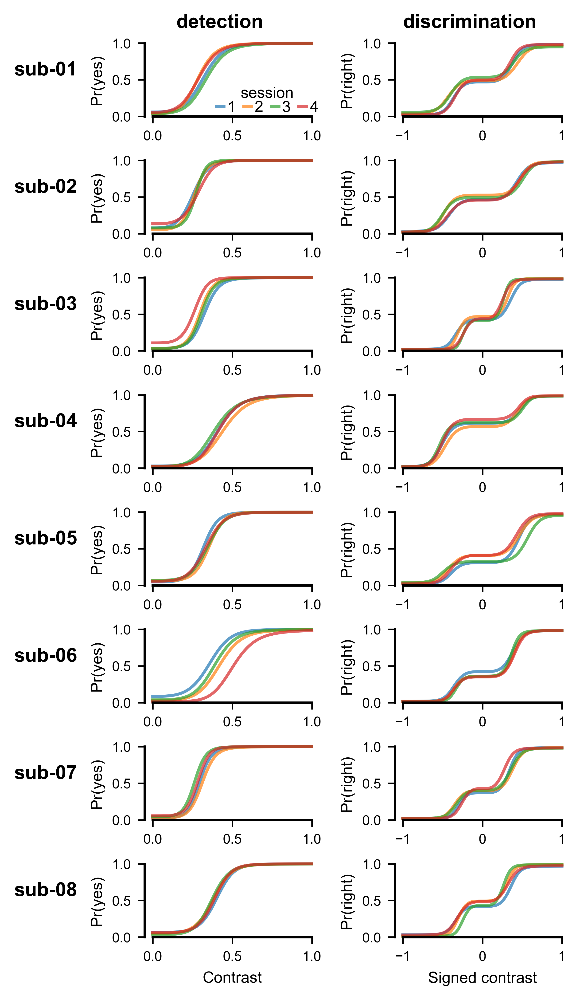

In [326]:
fig = plt.figure(figsize=(17.6*CM*.6,17.5*CM), dpi=min_dpi)
sf = fig.subfigures(1,3, width_ratios=[1.03,3,3])

axs = []
for i in range(3):
    axs.append(sf[i].subplots(8,1))
    sf[i].suptitle(['', 'detection','discrimination'][i], x=.5, y=1, va='top', ha='center', fontsize=10)

ax = axs[0]
for i in range(8):
    ax[i].set_title(f'sub-0{i+1}', x=-.2, y=.4, fontsize=10, ha='left')
    ax[i].spines[['left','bottom']].set_visible(False)
    ax[i].set_xticks([])
    ax[i].set_yticks([])

for i, (m, n) in enumerate(zip(datanames, datacodes)):
    if n == '2afc':
        c = xr.DataArray(np.linspace(-1,1,100))
        c1 = np.maximum(0,-c)
        c2 = np.maximum(0,c)
        p = beh_idata[n].posterior.copy()
        d1 = 5 * c1**p['n'] / (p['c50']**p['n'] + c1**p['n'])
        d2 = 5 * c2**p['n'] / (p['c50']**p['n'] + c2**p['n'])
        psi = p['eps'].values + (1-2*p['eps'].values)*st.norm.cdf(((d2-d1)-p['b0']) / np.sqrt(2))

    else:
        c = xr.DataArray(np.linspace(0,1,100))
        p = beh_idata[n].posterior.copy()
        d = 5 * c**p['n'] / (p['c50']**p['n'] + c**p['n'])
        psi = st.norm.cdf(d - p['b0'])

    psi = psi.mean(axis=(1,2))
    ax = axs[i+1]

    for j in range(8):
        for k in range(4):
            ax[j].plot(c, psi[:,j*4+k], alpha=.7, clip_on=False)
        
        ax[j].set_ylim([0,1])
        ax[j].spines['bottom'].set_bounds([0,1] if n=='1ifc' else [-1,1])
        ax[j].set_ylabel('Pr(yes)' if n=='1ifc' else 'Pr(right)')

        if j==7:
            ax[j].set_xlabel('Contrast' if n=='1ifc' else 'Signed contrast')
    
    if n=='1ifc':
        ax[0].legend(np.arange(1,5), frameon=False, ncols=4, title='session', borderpad=.1, labelspacing=0, columnspacing=.5, borderaxespad=0, handlelength=.5, handletextpad=.2)

fig.subplots_adjust(hspace=.6, top=.97, bottom=.05, left=.2)
fig.savefig(f'supp-fig-psyc-fits.png')